# 01 · Data overview

**Question.** What does the event set behind every later notebook look like: how many police bulletins survive each cleaning step, how they split by crime group, year and month, how they spread over the two areal supports (2,592 IBGE 2022 census tracts, 93 UTBs), and how many share an identical published coordinate ("stacked" street-level geocodes)?

**Method.** Descriptive counts only, no inference. The funnel is read from `outputs/data/funnel.json` (written by `scripts/02_clean/clean_bulletins.py`) and **recomputed** here from the raw CSV and the cleaned parquet, so the two must agree. Per-unit counts come from `crime.data.unit_counts`; maps are plain geopandas / matplotlib with class breaks from mapclassify (Rey, S.J. et al., *mapclassify*, PySAL). Stacking is measured with `pandas.DataFrame.duplicated` on the published latitude/longitude.

**Data.** `crime.data` (EPSG:31983, metres): `load_points`, `load_units`, `unit_counts`, plus the stage-02 parquet for the bulletins without a coordinate. Study window 2022-01-01 … 2025-12-31 by occurrence date.

In [1]:
import json

import mapclassify
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from crime.core.config import BULLETINS_PARQUET, NOTEBOOK_OUTPUTS_DIR, OUTPUTS_DIR
from crime.data import GROUPS, load_points, load_units, unit_counts
from crime.data.cleaning import DATE_END, DATE_START

import _mapstyle as ms  # notebooks/_mapstyle.py: basemap, overlay, graticule, scale bar, legends

OUT = NOTEBOOK_OUTPUTS_DIR / "01_data_overview"
OUT.mkdir(parents=True, exist_ok=True)
ms.setup()

# fixed colour per crime group (categorical slots in a fixed order, never cycled)
GROUP_COLORS = {"all": "#2a78d6", "property": "#eb6834", "bodily_harm": "#1baf7a",
                "traffic": "#eda100", "drug": "#e87ba4", "violent": "#008300", "sexual": "#6250d6"}
GROUP_LABEL = {"all": "All groups", "property": "Property", "bodily_harm": "Bodily harm",
               "traffic": "Traffic", "drug": "Drug", "violent": "Violent", "sexual": "Sexual"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})

def save(fig, name):
    for ax in fig.axes:                       # one tick per year on time axes
        if isinstance(ax.xaxis.get_major_formatter(), (mdates.AutoDateFormatter, mdates.ConciseDateFormatter)):
            ax.xaxis.set_major_locator(mdates.YearLocator())
            ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    # save as 300-dpi PNG in OUT, show inline, then free the figure
    fig.savefig(OUT / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("window:", DATE_START, "..", DATE_END)

window: 2022-01-01 .. 2025-12-31


## 1. Funnel: raw offence records → geocoded in-tract bulletins

Stages as defined in `outputs/data/funnel.json`. Each count is recomputed below from the raw CSV (`outputs/data/crimes_campinas.csv`) and the cleaned parquet, and the notebook stops if a number disagrees.

In [2]:
funnel = pd.DataFrame(json.loads((OUTPUTS_DIR / "data" / "funnel.json").read_text()))

raw = pd.read_csv(OUTPUTS_DIR / "data" / "crimes_campinas.csv", usecols=[0], low_memory=False)
b = pd.read_parquet(BULLETINS_PARQUET)
in_window = b["DATA_OCORRENCIA_BO"].between(pd.Timestamp(DATE_START), pd.Timestamp(DATE_END))
w = b[in_window]
usable = w["COORD_STATUS"].isin(["ok", "fixed_decimal"])
in_tract = w["cd_setor"].notna()
pts = load_points("all")

recomputed = [len(raw), len(b), len(w), int(usable.sum()), int(in_tract.sum())]
funnel["recomputed"] = recomputed
funnel["dropped_from_previous"] = funnel["all"].diff().fillna(0).astype(int).mul(-1)
funnel["share_of_raw_%"] = (100 * funnel["all"] / funnel["all"].iloc[0]).round(1)
assert (funnel["all"] == funnel["recomputed"]).all(), funnel
assert len(pts) == funnel["all"].iloc[-1]
funnel.to_csv(OUT / "funnel.csv", index=False)
funnel[["stage", "all", "recomputed", "dropped_from_previous", "share_of_raw_%", "property"]]

,stage,all,recomputed,dropped_from_previous,share_of_raw_%,property
0,offence records (acquired CSV),139301,139301,0,100.0,109708
1,bulletins (one row per NUM_BO+ANO_BO+NOME_DELE...,138330,138330,971,99.3,109632
2,occurrence date in window,137323,137323,1007,98.6,108914
3,... with a usable coordinate,107912,107912,29411,77.5,90463
4,... inside a 2022 Campinas tract (cube input),107859,107859,53,77.4,90436


COORD_STATUS of in-window bulletins:
COORD_STATUS
ok               107184
redacted          12721
missing           11137
zero               5523
fixed_decimal       728
invalid              30


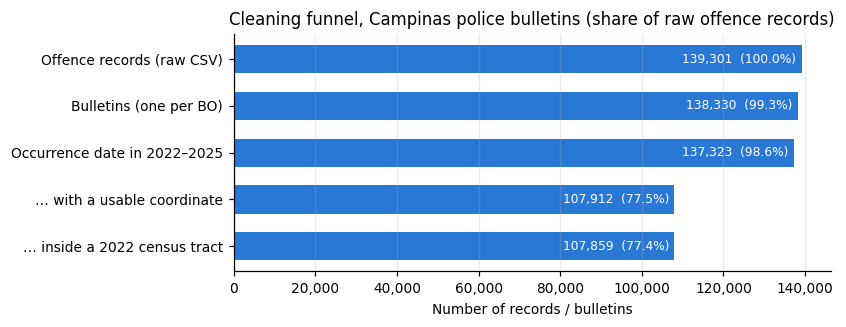

In [3]:
print("COORD_STATUS of in-window bulletins:")
print(w["COORD_STATUS"].value_counts().to_string())
fig, ax = plt.subplots(figsize=(7, 2.8))
lab = ["Offence records (raw CSV)", "Bulletins (one per BO)", "Occurrence date in 2022–2025",
       "… with a usable coordinate", "… inside a 2022 census tract"]
y = np.arange(len(lab))[::-1]
ax.barh(y, funnel["all"], color=GROUP_COLORS["all"], height=0.6)
for yi, v, s in zip(y, funnel["all"], funnel["share_of_raw_%"]):
    ax.text(v * 0.99, yi, f"{v:,}  ({s}%)", va="center", ha="right", color="white", fontsize=8)
ax.set_yticks(y, lab)
ax.set_xlabel("Number of records / bulletins")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_title("Cleaning funnel, Campinas police bulletins (share of raw offence records)")
ax.grid(axis="y", visible=False)
save(fig, "funnel")

## 2. Geocoding share by crime group

Share of in-window bulletins of each group that end up in the spatial event set (geocoded inside a tract). `sexual` has no published coordinates and is temporal only.

In [4]:
geo = (w.assign(in_tract=in_tract)
         .groupby("crime_group", observed=True)["in_tract"].agg(bulletins_in_window="size", in_tract="sum"))
geo.loc["all (every group)"] = [len(w), int(in_tract.sum())]
geo["share_in_tract_%"] = (100 * geo["in_tract"] / geo["bulletins_in_window"]).round(1)
geo = geo.astype({"bulletins_in_window": int, "in_tract": int})
geo.to_csv(OUT / "geocoding_share_by_group.csv")
geo.sort_values("bulletins_in_window", ascending=False)

,bulletins_in_window,in_tract,share_in_tract_%
crime_group,,,
all (every group),137323,107859,78.5
property,108914,90436,83.0
bodily_harm,15246,6590,43.2
traffic,6541,6302,96.3
drug,4705,4032,85.7
sexual,1211,0,0.0
violent,706,499,70.7


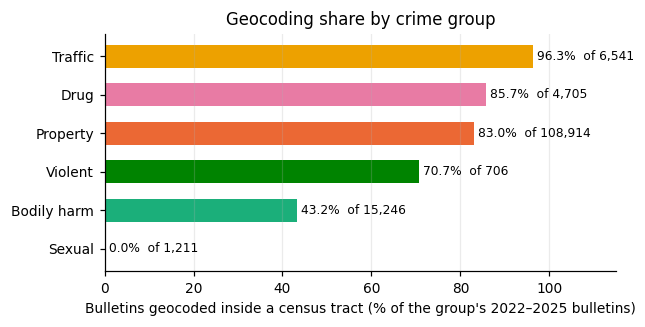

In [5]:
g = geo.drop("all (every group)").sort_values("share_in_tract_%")
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.barh([GROUP_LABEL[i] for i in g.index], g["share_in_tract_%"],
        color=[GROUP_COLORS[i] for i in g.index], height=0.6)
for i, (v, n) in enumerate(zip(g["share_in_tract_%"], g["bulletins_in_window"])):
    ax.text(v + 1, i, f"{v:.1f}%  of {n:,}", va="center", fontsize=8)
ax.set_xlim(0, 115)
ax.set_xlabel("Bulletins geocoded inside a census tract (% of the group's 2022–2025 bulletins)")
ax.set_title("Geocoding share by crime group")
ax.grid(axis="y", visible=False)
save(fig, "geocoding_share_by_group")

## 3. Counts per group and year (spatial event set)

In [6]:
by_year = pd.crosstab(pts["group"], pts["date"].dt.year, margins=True, margins_name="total")
by_year = by_year.rename(index={"total": "all"}).loc[list(GROUPS)]
by_year.columns = [str(c) for c in by_year.columns]
by_year.to_csv(OUT / "counts_group_year.csv")
by_year

,2022,2023,2024,2025,total
group,,,,,
all,26607,29158,27142,24952,107859
property,22845,24853,22616,20122,90436
bodily_harm,1479,1577,1650,1884,6590
traffic,1412,1673,1625,1592,6302
drug,729,931,1135,1237,4032
violent,142,124,116,117,499


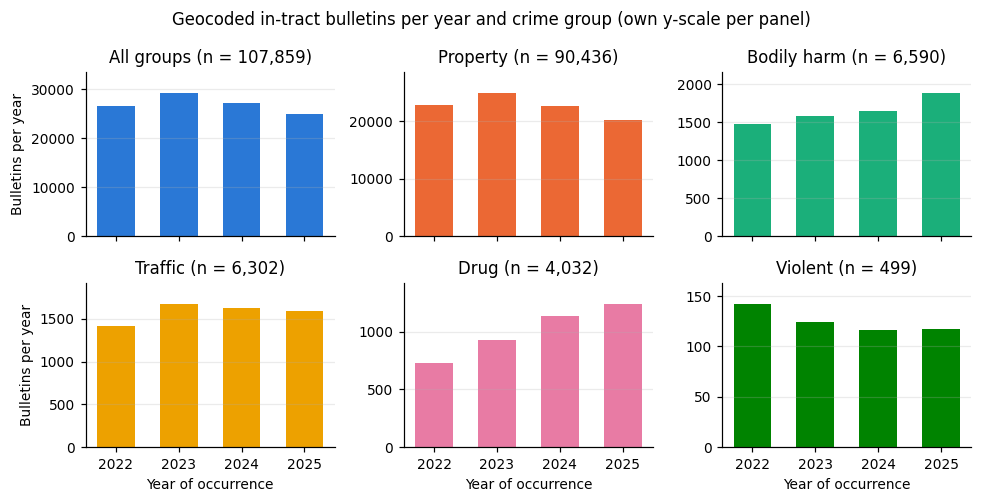

In [7]:
years = [c for c in by_year.columns if c != "total"]
fig, axes = plt.subplots(2, 3, figsize=(9, 4.6), sharex=True)
for ax, grp in zip(axes.flat, GROUPS):
    v = by_year.loc[grp, years]
    ax.bar(years, v, color=GROUP_COLORS[grp], width=0.6)
    ax.set_title(f"{GROUP_LABEL[grp]} (n = {by_year.loc[grp, 'total']:,})")
    ax.set_ylim(0, v.max() * 1.15)
    ax.grid(axis="x", visible=False)
for ax in axes[:, 0]:
    ax.set_ylabel("Bulletins per year")
for ax in axes[1]:
    ax.set_xlabel("Year of occurrence")
fig.suptitle("Geocoded in-tract bulletins per year and crime group (own y-scale per panel)")
fig.tight_layout()
save(fig, "counts_group_year")

## 4. Monthly series per group

Monthly totals of the in-tract event set (`unit_counts("tract", g, freq="M")` summed over tracts; the same totals on every support). The STL decomposition of these series is notebook `02_stl`.

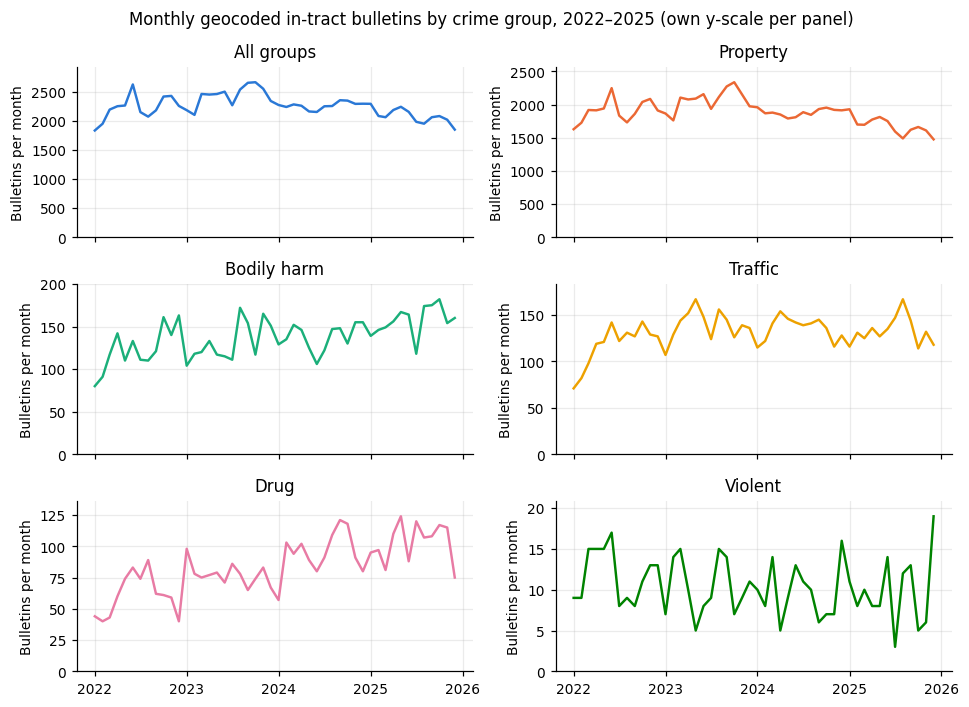

,all,property,bodily_harm,traffic,drug,violent
count,48.0,48.0,48.0,48.0,48.0,48.0
mean,2247.1,1884.1,137.3,131.3,84.0,10.4
std,196.0,194.2,23.8,18.4,22.1,3.6
min,1833.0,1476.0,80.0,71.0,40.0,3.0
25%,2137.0,1759.5,117.8,122.0,73.2,8.0
50%,2251.5,1883.0,139.5,131.5,82.0,10.0
75%,2347.8,1963.8,155.0,143.2,99.0,13.2
max,2662.0,2338.0,182.0,167.0,124.0,19.0


In [8]:
monthly = pd.DataFrame({g: unit_counts("tract", g, freq="M").sum(axis=0) for g in GROUPS})
monthly.index.name = "month"
assert monthly.sum().to_dict() == by_year["total"].to_dict()
monthly.to_csv(OUT / "monthly_counts_by_group.csv")
fig, axes = plt.subplots(3, 2, figsize=(9, 6.5), sharex=True)
for ax, grp in zip(axes.flat, GROUPS):
    ax.plot(monthly.index, monthly[grp], color=GROUP_COLORS[grp], lw=1.6)
    ax.set_title(GROUP_LABEL[grp])
    ax.set_ylim(0, monthly[grp].max() * 1.1)
    ax.set_ylabel("Bulletins per month")
fig.suptitle("Monthly geocoded in-tract bulletins by crime group, 2022–2025 (own y-scale per panel)")
fig.tight_layout()
save(fig, "monthly_counts_by_group")
monthly.describe().round(1)

## 5. Areal supports: census tracts and UTBs

In [9]:
tracts = load_units("tract")
utbs = load_units("utb")
areas = pd.DataFrame({s: u["area_km2"].describe(percentiles=[0.25, 0.5, 0.75])
                      for s, u in [("tract", tracts), ("utb", utbs)]}).T
areas["total_km2"] = [tracts["area_km2"].sum(), utbs["area_km2"].sum()]
areas.to_csv(OUT / "unit_areas_km2.csv")
areas.round(3)

,count,mean,std,min,25%,50%,75%,max,total_km2
tract,2592.0,0.307,1.689,0.001,0.027,0.063,0.117,32.108,794.800
utb,93.0,8.552,20.905,0.029,2.643,4.310,7.633,195.058,795.352


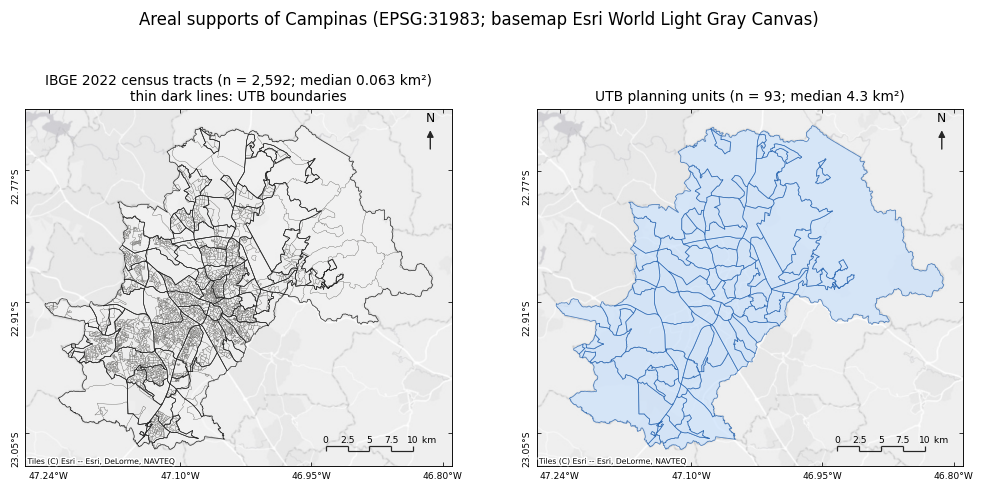

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
tracts.plot(ax=axes[0], facecolor="#f3f3f3", alpha=0.6, edgecolor="none")
tracts.boundary.plot(ax=axes[0], color="#52514e", lw=0.12)
axes[0].set_title(f"IBGE 2022 census tracts (n = {len(tracts):,}; median {tracts.area_km2.median():.3f} km²)\n"
                  "thin dark lines: UTB boundaries", fontsize=9)
utbs.plot(ax=axes[1], facecolor="#cde2fb", alpha=0.75, edgecolor="#1c5cab", lw=0.5)
axes[1].set_title(f"UTB planning units (n = {len(utbs)}; median {utbs.area_km2.median():.1f} km²)", fontsize=9)
ms.decorate(axes[0], tracts.crs, overlay=utbs)
ms.decorate(axes[1], utbs.crs)
fig.suptitle("Areal supports of Campinas (EPSG:31983; basemap Esri World Light Gray Canvas)")
save(fig, "supports_map")

## 6. Crime counts per unit, all groups, 2022–2025

Counts per unit (`unit_counts(support, "all")`) and, because units differ in size, the same count divided by the unit's area. Class breaks are quantiles (mapclassify), k = 5 on UTBs and 7 on tracts.

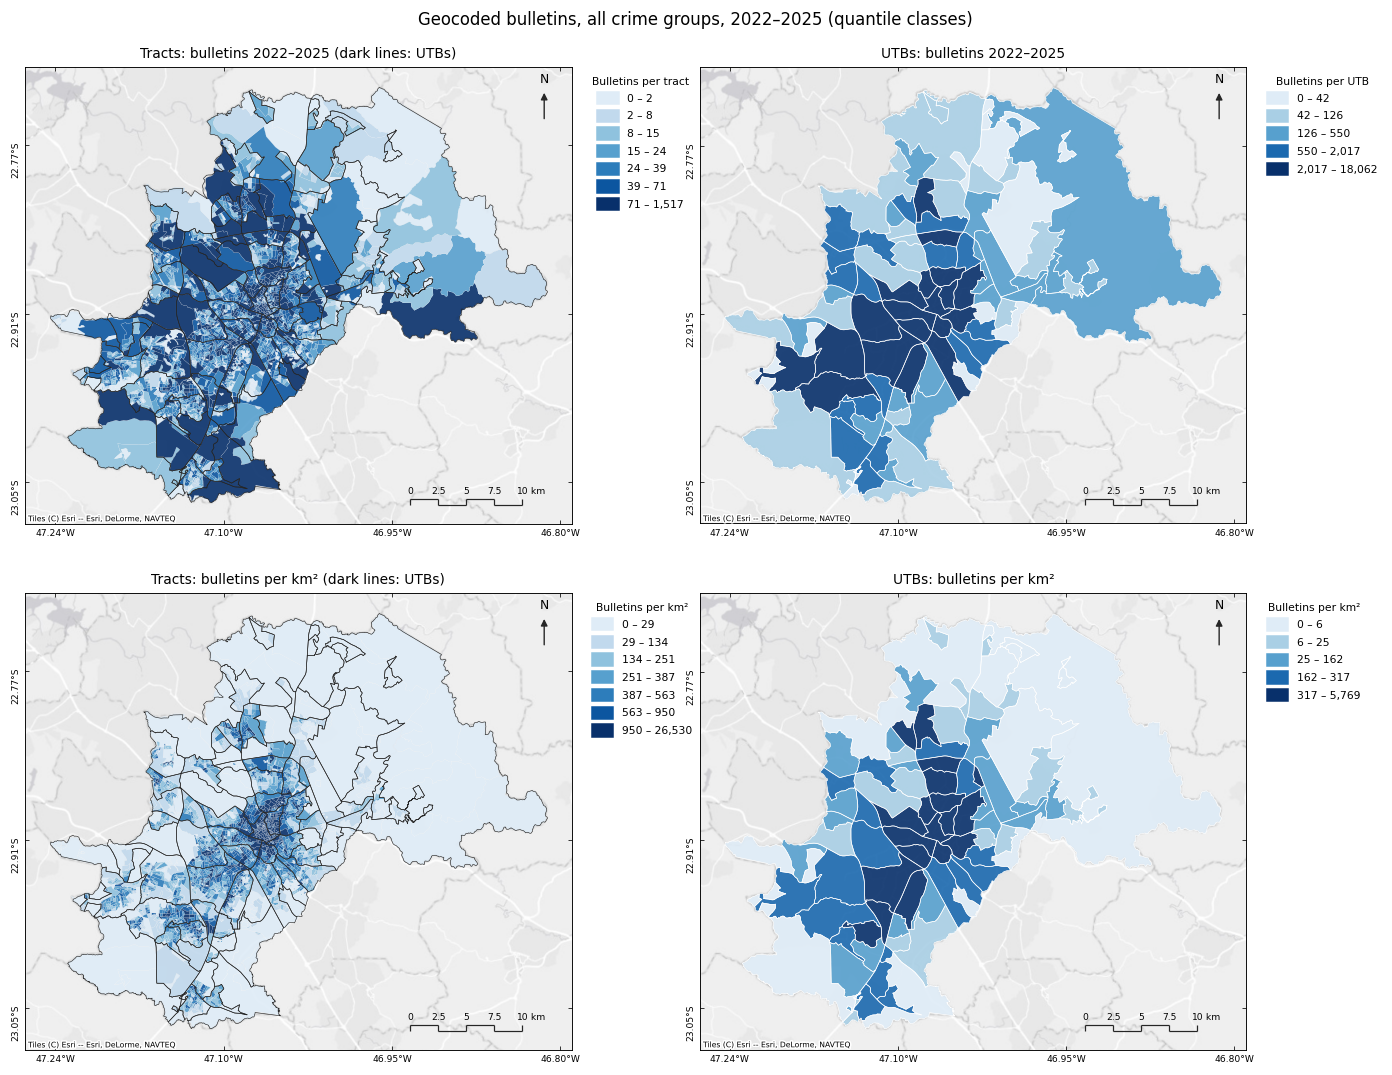

,units,units_with_0,median_count,max_count,top_10pct_units_share_%
tract,2592.0,186.0,19.0,1517.0,51.6
utb,93.0,5.0,276.0,18062.0,53.2


In [11]:
def choropleth(ax, gdf, col, k, title, legend_title):
    cls = mapclassify.Quantiles(gdf[col], k=k)
    pal = plt.cm.Blues(np.linspace(0.12, 1.0, len(cls.bins)))   # one colour per class, light -> dark
    tract = len(gdf) > 500
    gdf.plot(ax=ax, color=pal[cls.yb], edgecolor="none", alpha=0.9)
    gdf.boundary.plot(ax=ax, color="white", lw=0.05 if tract else 0.4)
    ms.decorate(ax, gdf.crs, overlay=utbs if tract else None)
    bins = np.r_[gdf[col].min(), cls.bins]
    handles = [plt.Rectangle((0, 0), 1, 1, color=pal[i]) for i in range(len(cls.bins))]
    labels = [f"{bins[i]:,.0f} – {bins[i+1]:,.0f}" for i in range(len(cls.bins))]
    ax.legend(handles, labels, title=legend_title, loc="upper left", bbox_to_anchor=(1.02, 1.0), fontsize=7,
              title_fontsize=7, frameon=False)
    ax.set_title(title + (" (dark lines: UTBs)" if tract else ""), fontsize=9)

counts = {}
for s, u in [("tract", tracts), ("utb", utbs)]:
    c = unit_counts(s, "all")
    u = u.set_index("unit_id").join(c.rename("count")).reset_index()
    u["per_km2"] = u["count"] / u["area_km2"]
    counts[s] = u
    u[["unit_id", "area_km2", "count", "per_km2"]].to_csv(OUT / f"counts_all_{s}.csv", index=False)
    assert u["count"].sum() == len(pts)

fig, axes = plt.subplots(2, 2, figsize=(12.5, 10))
choropleth(axes[0, 0], counts["tract"], "count", 7, "Tracts: bulletins 2022–2025", "Bulletins per tract")
choropleth(axes[0, 1], counts["utb"], "count", 5, "UTBs: bulletins 2022–2025", "Bulletins per UTB")
choropleth(axes[1, 0], counts["tract"], "per_km2", 7, "Tracts: bulletins per km²", "Bulletins per km²")
choropleth(axes[1, 1], counts["utb"], "per_km2", 5, "UTBs: bulletins per km²", "Bulletins per km²")
fig.suptitle("Geocoded bulletins, all crime groups, 2022–2025 (quantile classes)")
fig.tight_layout()
save(fig, "choropleth_all_tract_utb")
pd.DataFrame({s: {"units": len(u), "units_with_0": int((u["count"] == 0).sum()),
                  "median_count": u["count"].median(), "max_count": int(u["count"].max()),
                  "top_10pct_units_share_%": round(100 * u["count"].nlargest(int(np.ceil(len(u) / 10))).sum() / u["count"].sum(), 1)}
              for s, u in counts.items()}).T

## 7. Stacked geocodes

A bulletin is *stacked* when another bulletin in the event set has exactly the same published latitude/longitude (street-level geocoding puts many bulletins on one point). Two measures: identical published WGS84 coordinates (`LATITUDE`, `LONGITUDE` of the parquet) and identical projected EPSG:31983 coordinates rounded to 1 mm (what the point-pattern notebooks see).

In [12]:
ll = w.loc[in_tract, ["ANO_BO", "NUM_BO", "NOME_DELEGACIA", "LATITUDE", "LONGITUDE"]].copy()
ll["event_id"] = ll["ANO_BO"].astype("string") + "/" + ll["NUM_BO"].astype("string") + "/" + ll["NOME_DELEGACIA"]
p = pts[["event_id", "group", "utb"]].merge(ll[["event_id", "LATITUDE", "LONGITUDE"]], on="event_id", how="left")
assert len(p) == len(pts) and p["LATITUDE"].notna().all()
p["x_mm"] = np.round(pts.geometry.x.to_numpy(), 3)
p["y_mm"] = np.round(pts.geometry.y.to_numpy(), 3)

def stacked_row(d):
    st_ll = d.duplicated(["LATITUDE", "LONGITUDE"], keep=False)
    st_xy = d.duplicated(["x_mm", "y_mm"], keep=False)
    n_loc = d.groupby(["LATITUDE", "LONGITUDE"]).ngroups
    return pd.Series({"bulletins": len(d), "distinct_latlon": n_loc,
                      "stacked_latlon_%": round(100 * st_ll.mean(), 1),
                      "stacked_xy_1mm_%": round(100 * st_xy.mean(), 1),
                      "bulletins_per_location": round(len(d) / n_loc, 2)})

# stacking counted within the group (a property bulletin stacked only on a traffic one is not stacked within property)
stack = pd.DataFrame({g: stacked_row(p if g == "all" else p[p["group"] == g]) for g in GROUPS}).T
stack.to_csv(OUT / "stacked_geocodes_by_group.csv")
stack

,bulletins,distinct_latlon,stacked_latlon_%,stacked_xy_1mm_%,bulletins_per_location
all,107859.0,52616.0,63.1,65.2,2.05
property,90436.0,47220.0,59.7,62.0,1.92
bodily_harm,6590.0,4805.0,40.1,41.6,1.37
traffic,6302.0,4094.0,48.5,49.8,1.54
drug,4032.0,1966.0,65.3,67.0,2.05
violent,499.0,460.0,14.2,14.8,1.08


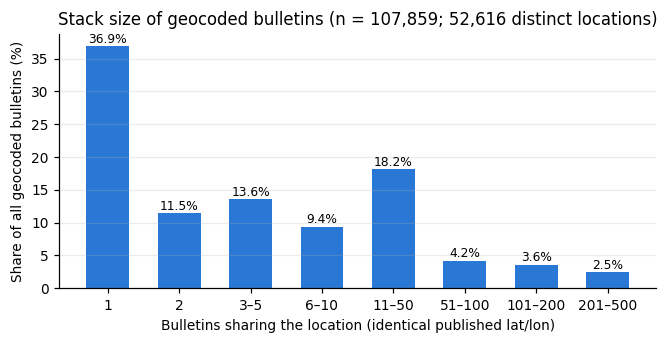

largest stacks (bulletins at one coordinate): [413, 408, 304, 294, 281, 261, 257, 247, 208, 176]


,locations,bulletins,bulletins_%
bulletins_at_location,,,
1,39824,39824,36.9
2,6224,12448,11.5
3–5,4076,14673,13.6
6–10,1360,10111,9.4
11–50,1024,19645,18.2
51–100,69,4560,4.2
101–200,30,3925,3.6
201–500,9,2673,2.5


In [13]:
sizes = p.groupby(["LATITUDE", "LONGITUDE"]).size()
dist = sizes.value_counts().sort_index()
size_bins = pd.cut(sizes, [0, 1, 2, 5, 10, 50, 100, 200, 500],
                   labels=["1", "2", "3–5", "6–10", "11–50", "51–100", "101–200", "201–500"])
tab = pd.DataFrame({"locations": sizes.groupby(size_bins, observed=False).size(),
                    "bulletins": sizes.groupby(size_bins, observed=False).sum()})
tab["bulletins_%"] = (100 * tab["bulletins"] / tab["bulletins"].sum()).round(1)
tab.index.name = "bulletins_at_location"
tab.to_csv(OUT / "stack_size_distribution.csv")

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(tab.index.astype(str), tab["bulletins_%"], color=GROUP_COLORS["all"], width=0.6)
for i, v in enumerate(tab["bulletins_%"]):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center", fontsize=8)
ax.set_xlabel("Bulletins sharing the location (identical published lat/lon)")
ax.set_ylabel("Share of all geocoded bulletins (%)")
ax.set_title(f"Stack size of geocoded bulletins (n = {len(p):,}; {len(sizes):,} distinct locations)")
ax.grid(axis="x", visible=False)
save(fig, "stack_size_distribution")
print("largest stacks (bulletins at one coordinate):", sizes.nlargest(10).to_list())
tab

In [14]:
top = (p.groupby(["LATITUDE", "LONGITUDE"]).agg(bulletins=("event_id", "size"), utb=("utb", "first"),
                                                  main_group=("group", lambda s: s.mode().iat[0]))
         .nlargest(15, "bulletins").reset_index())
top["share_of_all_%"] = (100 * top["bulletins"] / len(p)).round(2)
top.to_csv(OUT / "top_stacked_locations.csv", index=False)
top

,LATITUDE,LONGITUDE,bulletins,utb,main_group,share_of_all_%
0,-22.906276,-47.074759,413,Jd. Eulina/ Jd. Chapadão/ Bonfim,property,0.38
1,-22.904168,-47.065547,408,Centro,property,0.38
2,-22.907965,-47.059885,304,Centro,property,0.28
3,-23.011951,-47.143283,294,Aeroporto de Viracopos,property,0.27
4,-22.906000,-47.060877,281,Centro,property,0.26
5,-22.906218,-47.074478,261,Jd. Eulina/ Jd. Chapadão/ Bonfim,property,0.24
6,-22.977814,-47.109555,257,Jd. Maria Rosa/ Pq. São Paulo,property,0.24
7,-22.907397,-47.058473,247,Centro,property,0.23
8,-22.905870,-47.072520,208,Centro,property,0.19
9,-22.902237,-47.059797,176,Centro,property,0.16


## Findings

In [15]:
f = funnel.set_index("stage")["all"]
print(f"Funnel: {f.iloc[0]:,} offence records -> {f.iloc[1]:,} bulletins -> {f.iloc[2]:,} in 2022-2025 -> "
      f"{f.iloc[3]:,} with a usable coordinate -> {f.iloc[4]:,} in a census tract "
      f"({100*f.iloc[4]/f.iloc[2]:.1f}% of in-window bulletins). Recomputed counts match funnel.json.")
print("Geocoded share by group (%):", geo["share_in_tract_%"].to_dict())
print("Spatial event set by group:", by_year["total"].to_dict())
print("Per year (all):", by_year.loc["all", years].to_dict())
print(f"Stacked (identical lat/lon, all): {stack.loc['all','stacked_latlon_%']}%; projected 1 mm: {stack.loc['all','stacked_xy_1mm_%']}%; "
      f"{stack.loc['all','distinct_latlon']:,} distinct locations")
print(f"Largest stack: {sizes.max():,} bulletins ({100*sizes.max()/len(p):.1f}% of all) at one coordinate")

Funnel: 139,301 offence records -> 138,330 bulletins -> 137,323 in 2022-2025 -> 107,912 with a usable coordinate -> 107,859 in a census tract (78.5% of in-window bulletins). Recomputed counts match funnel.json.
Geocoded share by group (%): {'bodily_harm': 43.2, 'drug': 85.7, 'property': 83.0, 'sexual': 0.0, 'traffic': 96.3, 'violent': 70.7, 'all (every group)': 78.5}
Spatial event set by group: {'all': 107859, 'property': 90436, 'bodily_harm': 6590, 'traffic': 6302, 'drug': 4032, 'violent': 499}
Per year (all): {'2022': 26607, '2023': 29158, '2024': 27142, '2025': 24952}
Stacked (identical lat/lon, all): 63.1%; projected 1 mm: 65.2%; 52,616.0 distinct locations
Largest stack: 413 bulletins (0.4% of all) at one coordinate


_The text below was written from the numbers printed above (rerun → recheck)._

- **Funnel.** 139,301 offence records → 138,330 bulletins → 137,323 with an occurrence date in 2022–2025 → 107,912 with a usable coordinate → **107,859** inside a 2022 census tract (78.5 % of in-window bulletins). Every stage recomputed from the raw CSV and the parquet matches `funnel.json`. The main loss is coordinates: 29,411 in-window bulletins have a redacted (12,721), missing (11,137), zero (5,523) or invalid (30) coordinate; 53 more fall outside every tract.
- **Groups.** Property dominates (90,436 = 84 % of the spatial set); bodily harm 6,590, traffic 6,302, drug 4,032, violent 499. Geocoding share differs strongly: traffic 96 %, drug 86 %, property 83 %, violent 71 %, bodily harm 43 %, sexual 0 %. Spatial results for bodily harm therefore rest on fewer than half of its bulletins.
- **Years.** All groups: 26,607 (2022), 29,158 (2023), 27,142 (2024), 24,952 (2025). Property peaks in 2023 and falls in 2025; bodily harm (1,479 → 1,884) and drug (729 → 1,237) rise every year; violent falls from 142 to ~117. The late-2025 months may still be depressed by reporting lag (`02_stl`).
- **Supports.** 2,592 tracts (median 0.063 km², max 32 km²) and 93 UTBs (median 4.3 km², max 195 km²); both cover ~795 km² and both sum to 107,859 bulletins. Counts are concentrated: the top 10 % of tracts hold 51.6 % of bulletins (186 tracts have none; max 1,517), the top 10 % of UTBs 53.2 % (max 18,062, 5 UTBs with none).
- **Stacked geocodes.** 63.1 % of geocoded bulletins share an identical published coordinate with another bulletin (65.2 % on projected coordinates rounded to 1 mm); 107,859 bulletins sit on 52,616 distinct locations. Stacking is strongest for drug (65 %) and property (60 %) and weakest for violent (14 %). The largest stack holds 413 bulletins at one coordinate; the top 15 stacks are mostly in the Centro UTB and mostly property. Point-pattern and Knox results must be read with this in mind.